In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("darkgrid")

df = pd.read_csv("retail_sales_dataset.csv")
df.head()
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 100.2 KB


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [35]:
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day_name()
df['Year'] = df['Date'].dt.year

In [ ]:
#To better understand customer demographics, ages were grouped into five brackets. This allows us to compare spending behavior across different life 
#stages rather than individual ages

In [36]:
bins = [18, 29, 39, 49, 59, 69]
labels = ["18-29", "30-39", "40-49", "50-59", "60-69"]

df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=True)
df['Age Group'].value_counts()

Age Group
18-29    230
40-49    222
50-59    221
30-39    191
60-69    115
Name: count, dtype: int64

In [27]:
#Revenue was engineered as a derived feature from Quantity × Price per Unit. This ensures consistency with Total Amount and allows for flexible 
#analysis across categories, customers, and time periods.

In [37]:
df['Revenue'] = df['Quantity'] * df['Price per Unit']

(df['Revenue'] == df['Total Amount']).value_counts()

True    1000
Name: count, dtype: int64

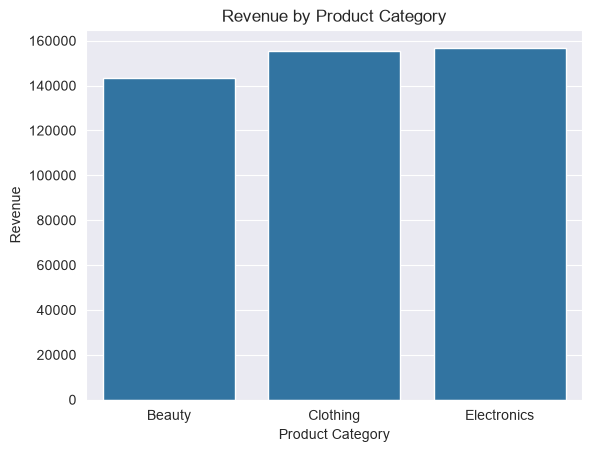

In [38]:
category_revenue = df.groupby("Product Category")["Revenue"].sum().reset_index()

sns.barplot(x="Product Category", y="Revenue", data=category_revenue)
plt.title("Revenue by Product Category")
plt.show()

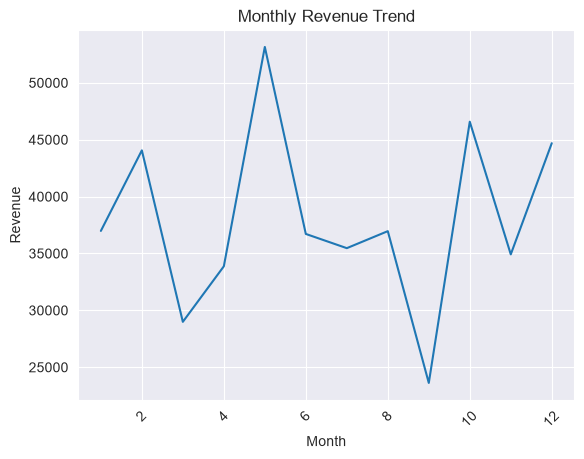

In [39]:
monthly_revenue = df.groupby("Month")["Revenue"].sum().reset_index()

sns.lineplot(x="Month", y="Revenue", data=monthly_revenue)
plt.title("Monthly Revenue Trend")
plt.xticks(rotation=45)
plt.show()

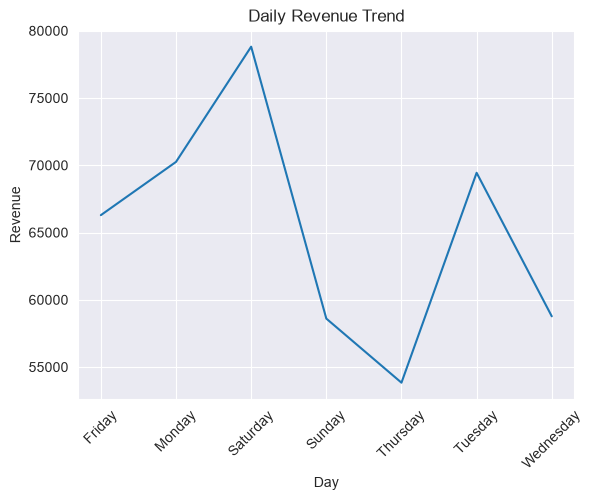

In [43]:
daily_revenue = df.groupby("Day")["Revenue"].sum().reset_index()

sns.lineplot(x="Day", y="Revenue", data=daily_revenue)
plt.title("Daily Revenue Trend")
plt.xticks(rotation=45)
plt.show()

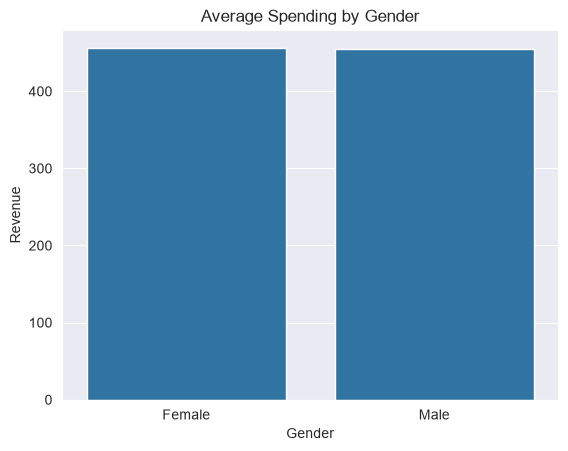

In [32]:
gender_spending = df.groupby("Gender")["Revenue"].mean().reset_index()

sns.barplot(x="Gender", y="Revenue", data=gender_spending)
plt.title("Average Spending by Gender")
plt.show()

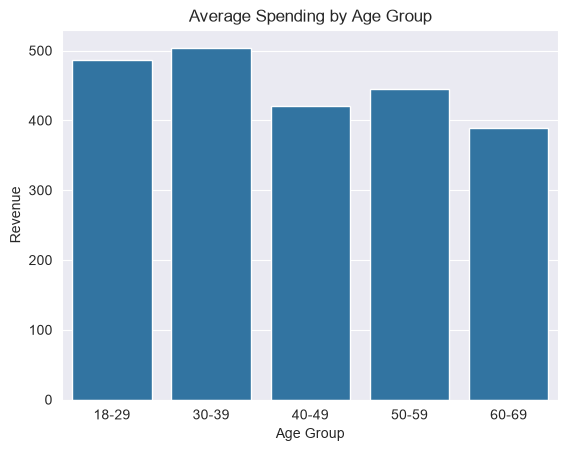

In [40]:
age_spending = df.groupby("Age Group")["Revenue"].mean().reset_index()

sns.barplot(x="Age Group", y="Revenue", data=age_spending)
plt.title("Average Spending by Age Group")
plt.show()

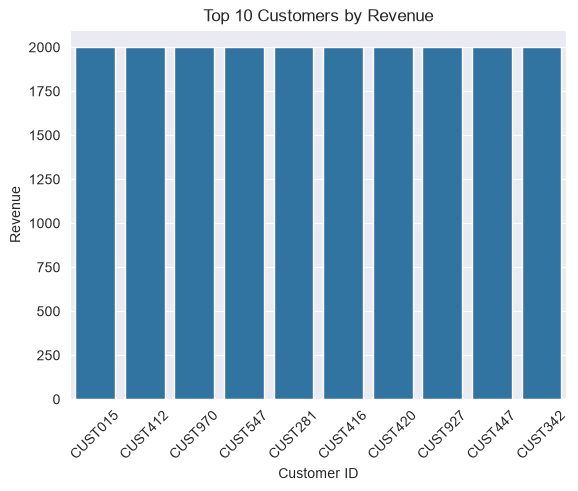

In [41]:
top_customers = df.groupby("Customer ID")["Revenue"].sum().reset_index().sort_values(by="Revenue", ascending=False).head(10)

sns.barplot(x="Customer ID", y="Revenue", data=top_customers)
plt.title("Top 10 Customers by Revenue")
plt.xticks(rotation=45)
plt.show()

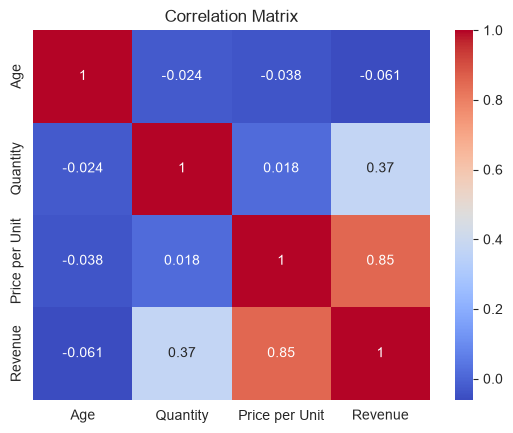

In [44]:
corr = df[["Age", "Quantity", "Price per Unit", "Revenue"]].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()